# Signal-discovery results: browse and compare

Choose discovery runs and a qrel source to compare ranked signals. The notebook reports macro-averaged nDCG at several cutoffs, shows qrel coverage when labels are missing, and lets you inspect each condition's ranked signals. Human qrels should be the primary evaluation; LLM qrels are useful comparisons.

Runs record their `signal_catalog`. **Path-aware** evaluates feature plus provenance path, including relationship signals. **Feature-collapsed** evaluates one direct candidate per physical table/column and uses only the matching direct-path qrels. Do not compare nDCG between these candidate universes as if they were the same task; compare methods within each view.

The compare-runs plot scores selected discovery runs against Human, GPT-6 Luna, and Muse Glimmer labels side by side. A final section also treats GPT-6 grades as a ranking and evaluates that ranking against human labels. The default results folder is results/rel-amazon/discovery/condition-v3-20261022/. Change RUN_DIR below to browse another folder.

In [39]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import clear_output, display, Markdown
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None  # Static tables remain usable when ipywidgets is unavailable.
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None  # Tables and browsing still work without the optional plot dependency.

REPO = Path.cwd()
if not (REPO / "src").is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from src.evaluation.ranking_metrics import ranking_metrics

RUN_DIR = REPO / "results/rel-amazon/discovery/condition-v3-catalog-views"
QREL_FILES = {
    "Human — Lysandre": REPO / "annotations/rel-amazon/human/lysandre.jsonl",
    "GPT-6 Luna": REPO / "annotations/rel-amazon/llm/signal-relevance-v7/gpt-6-luna.jsonl",
    "Muse Glimmer": REPO / "annotations/rel-amazon/llm/signal-relevance-v7/muse-glimmer-30b.jsonl",
}

def read_jsonl(path):
    with Path(path).open(encoding="utf-8") as stream:
        return [json.loads(line) for line in stream if line.strip()]

result_paths = sorted(RUN_DIR.glob("*.jsonl"))
qrel_files = {name: path for name, path in QREL_FILES.items() if path.exists()}
if not result_paths:
    raise FileNotFoundError(f"No discovery JSONL files in {RUN_DIR}. Set RUN_DIR to the folder containing your runs.")
if not qrel_files:
    raise FileNotFoundError("No configured qrel files were found; check QREL_FILES.")
print(f"{len(result_paths)} discovery run(s), {len(qrel_files)} qrel source(s)")
print(f"Results folder: {RUN_DIR}")

10 discovery run(s), 3 qrel source(s)
Results folder: /storage/lcostes/Similarity_benchmark/results/rel-amazon/discovery/condition-v3-catalog-views


In [40]:
def load_qrels(path, signal_catalog='path-aware'):
    rows = read_jsonl(path)
    expected, grades = {}, {}
    for row in rows:
        condition_id, candidate_id = row.get("condition_id"), row.get("candidate_id")
        if not isinstance(condition_id, str) or not isinstance(candidate_id, str):
            continue
        candidate = row.get("candidate")
        is_direct_attribute = (
            isinstance(candidate, dict)
            and candidate.get("kind") == "attribute"
            and isinstance(candidate.get("path"), list)
            and len(candidate["path"]) == 1
        )
        if signal_catalog == "feature-collapsed" and not is_direct_attribute:
            continue
        expected.setdefault(condition_id, set()).add(candidate_id)
        grade = row.get("grade")
        if row.get("status") in {"judged", "complete"} and type(grade) is int:
            grades.setdefault(condition_id, {})[candidate_id] = grade
    return grades, expected

def evaluate_run(result_path, qrel_path):
    result_rows = read_jsonl(result_path)
    condition_rows = []
    for run in result_rows:
        condition_id = run.get("condition_id")
        signal_catalog = run.get("signal_catalog", "path-aware")
        judgments, expected = load_qrels(qrel_path, signal_catalog)
        grades = judgments.get(condition_id, {})
        if not grades:
            continue
        all_ids = expected.get(condition_id, set())
        coverage = len(grades) / len(all_ids) if all_ids else 0.0
        signals = run.get("signals") or []
        ranked = [item["id"] for item in signals if isinstance(item, dict) and isinstance(item.get("id"), str)]
        # Exclude unjudged IDs; never silently score them as grade 0.
        ranked_judged = [candidate_id for candidate_id in ranked if candidate_id in grades]
        metrics = ranking_metrics(ranked_judged, grades)
        method_kind = run.get("method", "rank")
        method = run.get("scorer", "unknown") if method_kind == "rank" else method_kind
        condition_rows.append({
            "condition_id": condition_id,
            "condition": run.get("condition", ""),
            "method": method,
            "signal_catalog": signal_catalog,
            "qrel_coverage": coverage,
            "ranked_count": len(ranked),
            **metrics,
        })
    if not condition_rows:
        return None, pd.DataFrame()
    per_condition = pd.DataFrame(condition_rows)
    metric_columns = [
        column for column in per_condition.columns
        if column.startswith("ndcg@")
    ]
    summary = {column: per_condition[column].mean() for column in metric_columns}
    summary.update({
        "method": str(condition_rows[0]["method"]),
        "signal_catalog": str(condition_rows[0]["signal_catalog"]),
        "run_file": Path(result_path).name,
        "conditions": len(condition_rows),
        "mean_qrel_coverage": per_condition["qrel_coverage"].mean(),
    })
    return summary, per_condition

def make_comparison(qrel_name, selected_paths):
    rows, per_condition = [], []
    qrel_path = qrel_files[qrel_name]
    for path in selected_paths:
        summary, details = evaluate_run(path, qrel_path)
        if summary is not None:
            rows.append(summary)
            per_condition.append(details)
    return (
        pd.DataFrame(rows),
        pd.concat(per_condition, ignore_index=True) if per_condition else pd.DataFrame(),
    )

## Compare runs

All result files in the selected run folder are selected by default, so the ordinary rankers, graph search, oracle-root graph search, and random baseline appear together once their JSONL files are present. nDCG rewards putting higher-grade signals near the top; the different cutoffs show how ranking quality changes as more results are considered. Results are averaged across conditions; qrel coverage is the fraction of candidate labels available in the selected judgment file. The oracle root is a target-entity proxy for this diagnostic, not a human-validated gold starting table.

The comparison plot shows the selected runs against Human, GPT-6 Luna, and Muse Glimmer labels side by side, so you can see whether a method’s apparent performance depends on the judgment source.

In [41]:
run_options = [(path.stem, str(path)) for path in result_paths]
CATALOG_ORDER = ['path-aware', 'feature-collapsed']
CATALOG_TITLES = {
    'path-aware': 'Path-aware view — feature plus provenance path',
    'feature-collapsed': 'Feature-collapsed view — direct physical attributes only',
}

def render_catalog_plot(all_source_summary, catalog_view, metric_cols):
    catalog_rows = all_source_summary[all_source_summary['signal_catalog'].eq(catalog_view)]
    if catalog_rows.empty or plt is None:
        return
    source_names = list(qrel_files)
    fig, axes = plt.subplots(1, len(source_names), figsize=(6 * len(source_names), 4), sharey=True)
    if len(source_names) == 1:
        axes = [axes]
    handles, labels = [], []
    x = list(range(len(metric_cols)))
    for ax, source_name in zip(axes, source_names):
        source_rows = catalog_rows[catalog_rows['label source'].eq(source_name)]
        for _, run_row in source_rows.iterrows():
            line, = ax.plot(x, [run_row[column] for column in metric_cols], marker='o', linewidth=1.7, label=run_row['run_file'])
            if source_name == source_names[0]:
                handles.append(line)
                labels.append(run_row['run_file'])
        ax.set_title(source_name)
        ax.set_xticks(x, [column.upper() for column in metric_cols])
        ax.set_ylim(0, 1)
        ax.set_ylabel('Macro nDCG')
        ax.grid(axis='y', alpha=0.25)
    fig.suptitle(CATALOG_TITLES.get(catalog_view, catalog_view))
    if handles:
        fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5), title='Run')
    fig.tight_layout(rect=(0, 0, 0.84, 0.93))
    plt.show()

def render_comparison(qrel_name, selected_paths):
    summary, per_condition = make_comparison(qrel_name, selected_paths)
    if summary.empty:
        print('No comparable result rows found.')
        return
    all_source_rows = []
    for source_name, source_path in qrel_files.items():
        for run_path in selected_paths:
            source_summary, _ = evaluate_run(run_path, source_path)
            if source_summary is not None:
                all_source_rows.append({'label source': source_name, **source_summary})
    all_source_summary = pd.DataFrame(all_source_rows)
    metric_cols = sorted(
        [column for column in summary.columns if column.startswith('ndcg@')],
        key=lambda name: int(name.split('@')[1]),
    )
    catalog_views = [view for view in CATALOG_ORDER if view in set(summary['signal_catalog'])]
    catalog_views += sorted(set(summary['signal_catalog']) - set(catalog_views))
    for catalog_view in catalog_views:
        catalog_summary = summary[summary['signal_catalog'].eq(catalog_view)].copy()
        catalog_conditions = per_condition[per_condition['signal_catalog'].eq(catalog_view)].copy()
        display(Markdown(f"## {CATALOG_TITLES.get(catalog_view, catalog_view)}"))
        display(Markdown(f"### Metrics against {qrel_name}"))
        display(catalog_summary.drop(columns='signal_catalog').sort_values('ndcg@5', ascending=False).round(3).reset_index(drop=True))
        render_catalog_plot(all_source_summary, catalog_view, metric_cols)
        display(Markdown('### Per-condition metrics'))
        ndcg_columns = [column for column in catalog_conditions.columns if column.startswith('ndcg@')]
        display(catalog_conditions[['method', 'condition_id', 'qrel_coverage', *ndcg_columns]].sort_values(['condition_id', 'method']).round(3).reset_index(drop=True))

if widgets is None:
    print("ipywidgets is unavailable; showing all runs against the human qrels. Edit qrel_name/selected_paths and rerun this cell to change the view.")
    qrel_name = next((name for name in qrel_files if name.startswith("Human")), next(iter(qrel_files)))
    selected_paths = [str(path) for path in result_paths]
    render_comparison(qrel_name, selected_paths)
else:
    qrel_picker = widgets.Dropdown(options=list(qrel_files), value=next(iter(qrel_files)), description="Labels:")
    run_picker = widgets.SelectMultiple(options=run_options, value=tuple(path for _, path in run_options), description="Runs:", layout=widgets.Layout(width="70%", height="130px"))
    comparison_output = widgets.Output()
    def refresh_comparison(change=None):
        with comparison_output:
            clear_output(wait=True)
            render_comparison(qrel_picker.value, run_picker.value)
    qrel_picker.observe(refresh_comparison, names="value")
    run_picker.observe(refresh_comparison, names="value")
    display(widgets.VBox([qrel_picker, run_picker, comparison_output]))
    refresh_comparison()

## Grades of top-ranked signals for a selected method

Select a method and condition to see its top five signals with Human, GPT-6 Luna, and Muse Glimmer grades. The cell also summarizes how many signals each source gave grades 3, 2, 1, and 0, and lists the selected method's rank positions for every grade-3 signal. For graph methods, positions are within the discovered shortlist.

In [42]:
TOP_SIGNALS_TO_SHOW = 5

def _run_method_name(run):
    method_kind = run.get("method", "rank")
    return run.get("scorer", "unknown") if method_kind == "rank" else method_kind

top_method_options = []
method_label_counts = {}
for result_path in result_paths:
    run_rows = read_jsonl(result_path)
    if not run_rows:
        continue
    label = _run_method_name(run_rows[0])
    method_label_counts[label] = method_label_counts.get(label, 0) + 1
    top_method_options.append((label, str(result_path)))
top_method_options = [
    (f"{label} — {Path(path).stem}" if method_label_counts[label] > 1 else label, path)
    for label, path in top_method_options
]

def render_top_signal_grades(result_path, condition_id):
    run = next((row for row in read_jsonl(result_path) if row.get("condition_id") == condition_id), None)
    if run is None:
        print("No results for this condition in the selected method.")
        return
    display(Markdown(f"### {_run_method_name(run)} — {condition_id}: {run.get('condition', '')}"))
    qrel_grades = {
        label: load_qrels(path)[0].get(condition_id, {})
        for label, path in qrel_files.items()
    }
    display(Markdown("</br>"))
    display(Markdown("#### Grade distribution for all labeled signals in this condition"))
    grade_counts = []
    for label, grades in qrel_grades.items():
        grade_counts.append({
            "label source": label,
            "grade 3": sum(grade == 3 for grade in grades.values()),
            "grade 2": sum(grade == 2 for grade in grades.values()),
            "grade 1": sum(grade == 1 for grade in grades.values()),
            "grade 0": sum(grade == 0 for grade in grades.values()),
        })
    display(pd.DataFrame(grade_counts).set_index("label source"))
    rows = []
    ranked_signals = run.get("signals") or []
    for rank, signal in enumerate(ranked_signals[:TOP_SIGNALS_TO_SHOW], 1):
        candidate_id = signal.get("id", "")
        item = {
            "rank": rank,
            "signal ID": candidate_id,
            "signal meaning": signal.get("human_explanation", ""),
        }
        for label, grades in qrel_grades.items():
            item[f"{label} grade"] = grades.get(candidate_id, "unjudged")
        rows.append(item)
    if rows:
        display(pd.DataFrame(rows))
    else:
        print("This method returned no ranked signals for the selected condition.")
    grade_three_positions = []
    for rank, signal in enumerate(ranked_signals, 1):
        candidate_id = signal.get("id", "")
        for label, grades in qrel_grades.items():
            if grades.get(candidate_id) == 3:
                grade_three_positions.append({
                    "rank in method": rank,
                    "label source": label,
                    "signal ID": candidate_id,
                    "signal meaning": signal.get("human_explanation", ""),
                })
    display(Markdown("#### Positions of grade-3 signals in this method's ranking"))
    if grade_three_positions:
        display(pd.DataFrame(grade_three_positions).sort_values(["rank in method", "label source"]).reset_index(drop=True))
    else:
        print("No returned signal has grade 3 under these label sources for this condition.")

if widgets is None:
    print("ipywidgets is unavailable; showing the first method and condition.")
    default_path = top_method_options[0][1]
    default_condition = read_jsonl(default_path)[0]["condition_id"]
    render_top_signal_grades(default_path, default_condition)
else:
    top_method_picker = widgets.Dropdown(options=top_method_options, description="Method:", layout=widgets.Layout(width="75%"))
    top_condition_picker = widgets.Dropdown(description="Condition:", layout=widgets.Layout(width="75%"))
    top_grade_output = widgets.Output()
    def refresh_top_signal_grades(change=None):
        if top_method_picker.value is None or top_condition_picker.value is None:
            return
        with top_grade_output:
            clear_output(wait=True)
            render_top_signal_grades(top_method_picker.value, top_condition_picker.value)
    def update_top_condition_options(change=None):
        run_rows = read_jsonl(top_method_picker.value)
        options = [(f"{row.get('condition_id')} — {row.get('condition', '')}", row.get("condition_id")) for row in run_rows]
        top_condition_picker.options = options
        if options:
            top_condition_picker.value = options[0][1]
        refresh_top_signal_grades()
    top_method_picker.observe(update_top_condition_options, names="value")
    top_condition_picker.observe(refresh_top_signal_grades, names="value")
    display(widgets.VBox([top_method_picker, top_condition_picker, top_grade_output]))
    update_top_condition_options()

## Browse one ranked list

Select a run and condition to inspect candidate IDs, plain-language meaning, technical signal/path, score, and qrel grade. The graph-search method returns a shortlist; it does not rank undiscovered candidates.

In [43]:
def render_ranked_list(result_path, condition_id, qrel_name):
    rows = read_jsonl(result_path)
    run = next((row for row in rows if row.get("condition_id") == condition_id), None)
    if run is None:
        print("Choose a result and condition.")
        return
    grades, _ = load_qrels(qrel_files[qrel_name])
    condition_grades = grades.get(run["condition_id"], {})
    display(Markdown(f"### {run['condition_id']} — {run.get('condition', '')}"))
    items = []
    for rank, signal in enumerate(run.get("signals", []), 1):
        candidate_id = signal.get("id", "")
        items.append({"rank": rank, "qrel grade": condition_grades.get(candidate_id, "unjudged"), "kind": signal.get("kind"), "source": signal.get("source_table"), "candidate": candidate_id, "signal meaning": signal.get("human_explanation", ""), "technical path": signal.get("description", ""), "score": signal.get("score")})
    display(pd.DataFrame(items))
    if run.get("graph_search"):
        display(Markdown("#### Graph-search trace"))
        display(pd.json_normalize(run["graph_search"], sep="."))

if widgets is None:
    print("ipywidgets is unavailable; showing the first run and first condition. Edit these variables and rerun the cell to browse.")
    browse_result_path = str(result_paths[0])
    browse_condition_id = read_jsonl(browse_result_path)[0]["condition_id"]
    browse_qrel_name = next((name for name in qrel_files if name.startswith("Human")), next(iter(qrel_files)))
    render_ranked_list(browse_result_path, browse_condition_id, browse_qrel_name)
else:
    browse_run = widgets.Dropdown(options=run_options, description="Run:", layout=widgets.Layout(width="75%"))
    browse_condition = widgets.Dropdown(description="Condition:", layout=widgets.Layout(width="75%"))
    browse_output = widgets.Output()
    def update_condition_options(change=None):
        rows = read_jsonl(browse_run.value)
        options = [(f"{row.get('condition_id')} — {row.get('condition', '')}", row.get("condition_id")) for row in rows]
        browse_condition.options = options
        if options:
            browse_condition.value = options[0][1]
    def show_ranked_list(change=None):
        with browse_output:
            clear_output(wait=True)
            render_ranked_list(browse_run.value, browse_condition.value, qrel_picker.value)
    browse_run.observe(update_condition_options, names="value")
    browse_condition.observe(show_ranked_list, names="value")
    qrel_picker.observe(show_ranked_list, names="value")
    display(widgets.VBox([browse_run, browse_condition, browse_output]))
    update_condition_options()
    show_ranked_list()

### GPT-6-as-ranker versus discovery methods (human nDCG)

GPT-6 is ranked by its 0–3 relevance grades. Equal GPT-6 grades are tie-averaged; its unjudged pair is omitted from its ranking. Scores are macro-averaged over conditions.

,method,run_file,conditions,mean_qrel_coverage,ndcg@1,ndcg@3,ndcg@5,ndcg@10
0,strands-decider,decider-full-feature-collapsed.jsonl,5,1.000,1.000,0.942,0.887,0.955
1,decider-graph-reranked,decider-graph-feature-collapsed.jsonl,5,1.000,0.829,0.868,0.866,0.920
2,GPT-6 Luna (grade-ranked),—,5,0.995,0.810,0.800,0.803,0.836
3,strands-decider,decider-full-path-aware.jsonl,5,1.000,0.829,0.727,0.735,0.762
4,decider-graph-reranked-oracle-root,decider-graph-oracle-root-path-aware.jsonl,5,1.000,0.886,0.746,0.658,0.642
5,decider-graph-reranked,decider-graph-path-aware.jsonl,5,1.000,0.600,0.677,0.620,0.570
6,decider-graph-reranked-oracle-root,decider-graph-oracle-root-feature-collapsed.jsonl,5,1.000,0.600,0.492,0.497,0.484
7,minilm,minilm-feature-collapsed.jsonl,5,1.000,0.629,0.368,0.461,0.664
8,random,random-seed42-feature-collapsed.jsonl,5,1.000,0.429,0.326,0.424,0.590
9,random,random-seed42-path-aware.jsonl,5,1.000,0.257,0.318,0.350,0.356


#### GPT-6 grade-ranked nDCG against human labels by condition

,method,condition_id,shared judged signals,human qrel coverage,ndcg@1,ndcg@3,ndcg@5,ndcg@10
0,GPT-6 Luna (grade-ranked),condition-001,39,1.000,1.000,0.961,0.914,0.905
1,GPT-6 Luna (grade-ranked),condition-002,38,0.974,1.000,0.805,0.836,0.851
2,GPT-6 Luna (grade-ranked),condition-003,39,1.000,1.000,1.000,0.905,0.966
3,GPT-6 Luna (grade-ranked),condition-004,39,1.000,0.429,0.615,0.689,0.672
4,GPT-6 Luna (grade-ranked),condition-005,39,1.000,0.619,0.619,0.669,0.785


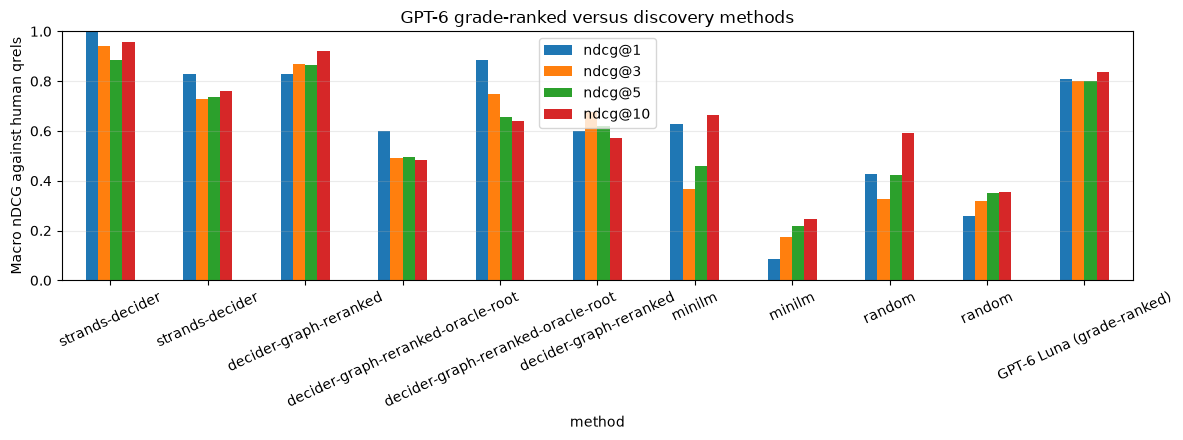

In [44]:
## GPT-6 grades used as a signal-ranking method, evaluated against human qrels

# This is a diagnostic comparison: GPT-6 judged each candidate signal, so rank
# signals by its grade and measure nDCG against the human annotations. Ties in
# GPT-6 grade are handled by expected DCG under a uniform random ordering within
# each tied group, rather than by an arbitrary candidate-ID ordering.

HUMAN_QREL_NAME = next((name for name in qrel_files if name.startswith("Human")), None)
GPT6_QREL_NAME = next((name for name in qrel_files if name.startswith("GPT-6")), None)
if HUMAN_QREL_NAME is None or GPT6_QREL_NAME is None:
    print("This comparison requires both human and GPT-6 qrel files.")
else:
    human_grades, human_expected = load_qrels(qrel_files[HUMAN_QREL_NAME])
    gpt6_grades, gpt6_expected = load_qrels(qrel_files[GPT6_QREL_NAME])

    def _expected_tie_ndcg(predicted_grades, truth_grades, k):
        """Expected nDCG@k when equal predicted grades are randomly ordered."""
        items = [(predicted, truth) for candidate_id, predicted in predicted_grades.items()
                 if candidate_id in truth_grades for truth in [truth_grades[candidate_id]]]
        if not items:
            return 0.0
        ideal_gains = sorted((2 ** grade - 1 for grade in truth_grades.values()), reverse=True)
        ideal_dcg = sum(gain / __import__("math").log2(rank + 2)
                        for rank, gain in enumerate(ideal_gains[:k]))
        if ideal_dcg == 0:
            return 0.0
        groups = {}
        for predicted, truth in items:
            groups.setdefault(predicted, []).append(2 ** truth - 1)
        dcg, next_rank = 0.0, 0
        for predicted in sorted(groups, reverse=True):
            gains = groups[predicted]
            end_rank = next_rank + len(gains)
            mean_gain = sum(gains) / len(gains)
            for zero_based_rank in range(next_rank, min(end_rank, k)):
                dcg += mean_gain / __import__("math").log2(zero_based_rank + 2)
            next_rank = end_rank
            if next_rank >= k:
                break
        return dcg / ideal_dcg

    gpt6_rows = []
    for condition_id in sorted(set(human_grades) & set(gpt6_grades)):
        truth = human_grades[condition_id]
        predicted = gpt6_grades[condition_id]
        shared = set(truth) & set(predicted)
        if not shared:
            continue
        # Keep every human-judged signal in the ideal denominator. If GPT-6 did not judge a candidate, it is absent from its predicted ranking and receives no rank credit.
        truth_shared = truth
        predicted_shared = {candidate_id: predicted[candidate_id] for candidate_id in shared}
        row = {
            "method": "GPT-6 Luna (grade-ranked)",
            "condition_id": condition_id,
            "shared judged signals": len(shared),
            "human qrel coverage": len(shared) / len(human_expected.get(condition_id, set())) if human_expected.get(condition_id) else 0.0,
        }
        for k in (1, 3, 5, 10):
            row[f"ndcg@{k}"] = _expected_tie_ndcg(predicted_shared, truth_shared, k)
        gpt6_rows.append(row)

    gpt6_per_condition = pd.DataFrame(gpt6_rows)
    if gpt6_per_condition.empty:
        print("No overlapping judged GPT-6 and human signals were found.")
    else:
        gpt6_summary = {column: gpt6_per_condition[column].mean()
                        for column in ["ndcg@1", "ndcg@3", "ndcg@5", "ndcg@10", "human qrel coverage"]}
        gpt6_summary.update({"method": "GPT-6 Luna (grade-ranked)", "conditions": len(gpt6_per_condition)})

        # Compare against the saved discovery methods, all scored on human qrels.
        human_run_summaries = []
        for result_path in result_paths:
            run_summary, _ = evaluate_run(result_path, qrel_files[HUMAN_QREL_NAME])
            if run_summary is not None:
                human_run_summaries.append(run_summary)
        comparison = pd.DataFrame(human_run_summaries + [gpt6_summary])
        display(Markdown("### GPT-6-as-ranker versus discovery methods (human nDCG)\n\nGPT-6 is ranked by its 0–3 relevance grades. Equal GPT-6 grades are tie-averaged; its unjudged pair is omitted from its ranking. Scores are macro-averaged over conditions."))
        display(comparison[["method", "run_file", "conditions", "mean_qrel_coverage", "ndcg@1", "ndcg@3", "ndcg@5", "ndcg@10"]].fillna({"run_file": "—", "mean_qrel_coverage": gpt6_summary["human qrel coverage"]}).sort_values("ndcg@5", ascending=False).round(3).reset_index(drop=True))
        display(Markdown("#### GPT-6 grade-ranked nDCG against human labels by condition"))
        display(gpt6_per_condition.round(3).reset_index(drop=True))
        if plt is not None:
            metric_cols = ["ndcg@1", "ndcg@3", "ndcg@5", "ndcg@10"]
            plot_data = comparison.set_index("method")[metric_cols]
            ax = plot_data.plot(kind="bar", figsize=(12, 4.5), ylim=(0, 1), ylabel="Macro nDCG against human qrels", rot=25,
                                title="GPT-6 grade-ranked versus discovery methods")
            ax.grid(axis="y", alpha=0.25)
            plt.tight_layout()
            plt.show()
